# AI Smart Electricity System — Bangladesh

**Task:** predict next month electricity usage, estimate the bill in BDT, and detect anomalies.
**Models:** Linear Regression, SVM, Random Forest, Decision Tree.
**Dataset:** Dhaka daily electricity demand + temperature (2021–2025, Kaggle).

The web app asks the user for their last 4 monthly bills (kWh), then predicts
next month's usage, the bill in BDT, and checks the latest month for anomalies.

## 1. Load and clean the data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PATH = "/kaggle/input/dhaka-2021-25-electricity-and-temperature-data/Updated_Final_Dataset_2021_2025.xlsx"
if not os.path.exists(PATH):
    PATH = "../data/Updated_Final_Dataset_2021_2025.xlsx"
    if not os.path.exists(PATH):
        PATH = "data/Updated_Final_Dataset_2021_2025.xlsx"

df = pd.read_excel(PATH, parse_dates=["Date"])
df = df[["Date", "Demand (MW)", "Temp (°C)", "Holiday"]].dropna().sort_values("Date")
df.columns = ["date", "demand_mw", "temp_c", "holiday"]
df = df.reset_index(drop=True)
print(df.shape)
df.tail(3)


(1759, 4)


,date,demand_mw,temp_c,holiday
1756,2025-10-23,5375.0,32,0
1757,2025-10-24,4581.0,33,0
1758,2025-10-25,5349.0,33,0


## 2. Make simple features

In [2]:
d = df.set_index("date")["demand_mw"]

F = pd.DataFrame(index=d.index)
F["temp"] = df.set_index("date")["temp_c"]
F["holiday"] = df.set_index("date")["holiday"].astype(int)
F["month"] = d.index.month
F["dayofweek"] = d.index.dayofweek
F["is_weekend"] = (d.index.dayofweek >= 5).astype(int)
F["lag_1"] = d.shift(1)
F["lag_7"] = d.shift(7)
F["roll_7"] = d.shift(1).rolling(7).mean()
F["demand"] = d
F = F.dropna()

FEATURES = ["temp", "holiday", "month", "dayofweek", "is_weekend", "lag_1", "lag_7", "roll_7"]
F.head(3)


,temp,holiday,month,dayofweek,is_weekend,lag_1,lag_7,roll_7,demand
date,,,,,,,,,
2021-01-08,28,0,1,4,0,3108.0,2386.0,2912.571429,2560.0
2021-01-09,27,0,1,5,1,2560.0,2868.0,2937.428571,3069.0
2021-01-10,27,0,1,6,1,3069.0,2918.0,2966.142857,3127.0


## 3. Train / test split (time based)

In [3]:
train = F[F.index <= "2024-12-31"]
test = F[F.index >= "2025-01-01"]
X_train, y_train = train[FEATURES], train["demand"]
X_test, y_test = test[FEATURES], test["demand"]
print("train:", len(train), "| test:", len(test))


train: 1454 | test: 298


## 4. Train the four models

In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "Linear Regression": LinearRegression(),
    "SVM": Pipeline([("scale", StandardScaler()),
                     ("svr", SVR(kernel="rbf", C=100))]),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
}

for name, m in models.items():
    m.fit(X_train, y_train)
    print("trained:", name)


trained: Linear Regression
trained: SVM


trained: Random Forest
trained: Decision Tree


## 5. Compare the models

In [5]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

rows, preds = [], {}
for name, m in models.items():
    p = preds[name] = pd.Series(m.predict(X_test), index=X_test.index)
    rows.append({
        "model": name,
        "RMSE": round(np.sqrt(mean_squared_error(y_test, p)), 1),
        "MAE": round(mean_absolute_error(y_test, p), 1),
        "MAPE (%)": round(np.mean(np.abs((y_test - p) / y_test)) * 100, 2),
        "R2": round(r2_score(y_test, p), 4),
    })

metrics = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
best_name = metrics.iloc[0]["model"]
best_model = models[best_name]
print("BEST MODEL:", best_name)
metrics


BEST MODEL: SVM


,model,RMSE,MAE,MAPE (%),R2
0,SVM,365.3,286.1,5.94,0.7179
1,Linear Regression,368.2,285.2,6.13,0.7135
2,Random Forest,415.7,310.5,6.48,0.6347
3,Decision Tree,605.9,412.6,8.67,0.2240


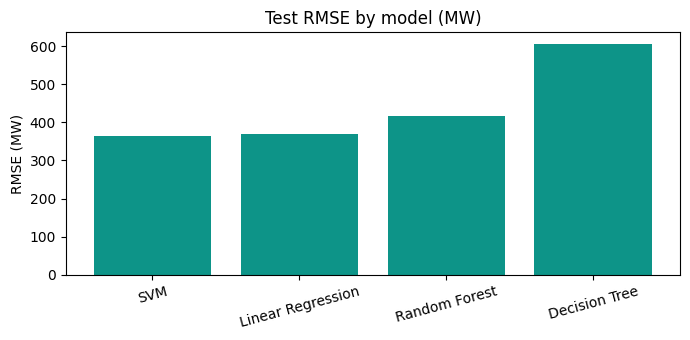

In [6]:
plt.figure(figsize=(7, 3.5))
plt.bar(metrics["model"], metrics["RMSE"], color="#0D9488")
plt.title("Test RMSE by model (MW)")
plt.ylabel("RMSE (MW)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## 6. Predict next month

In [7]:
hist = d.copy()
last_day = hist.index.max()
next_month = pd.date_range("2025-11-01", "2025-11-30", freq="D")

nov_temp = df[df.date.dt.month == 11]["temp_c"].mean()

cur = hist.copy()
days = []
for ts in pd.date_range(last_day + pd.Timedelta(days=1), next_month[-1], freq="D"):
    row = pd.DataFrame([{
        "temp": nov_temp, "holiday": 0,
        "month": ts.month, "dayofweek": ts.dayofweek,
        "is_weekend": int(ts.dayofweek >= 5),
        "lag_1": cur.iloc[-1], "lag_7": cur.iloc[-7], "roll_7": cur.iloc[-7:].mean(),
    }], columns=FEATURES)
    p = float(best_model.predict(row)[0])
    cur.loc[ts] = p
    days.append({"date": ts, "demand_mw": p})

fcast = pd.DataFrame(days).set_index("date")
fmonth = fcast.loc[next_month[0]:next_month[-1], "demand_mw"]


In [8]:
total_gwh = fmonth.sum() * 24 / 1000
avg_mw = fmonth.mean()
peak_day = fmonth.idxmax()
last_nov = d.loc["2024-11-01":"2024-11-30"]
yoy = (fmonth.sum() / last_nov.sum() - 1) * 100

print(f"Next month   : {next_month[0]:%B %Y}")
print(f"Total usage  : {total_gwh:,.0f} GWh")
print(f"Average load : {avg_mw:,.0f} MW")
print(f"Peak day     : {peak_day:%d %b} ({fmonth.max():,.0f} MW)")
print(f"vs Nov 2024  : {yoy:+.1f}%")


Next month   : November 2025
Total usage  : 3,092 GWh
Average load : 4,295 MW
Peak day     : 01 Nov (4,646 MW)
vs Nov 2024  : -1.8%


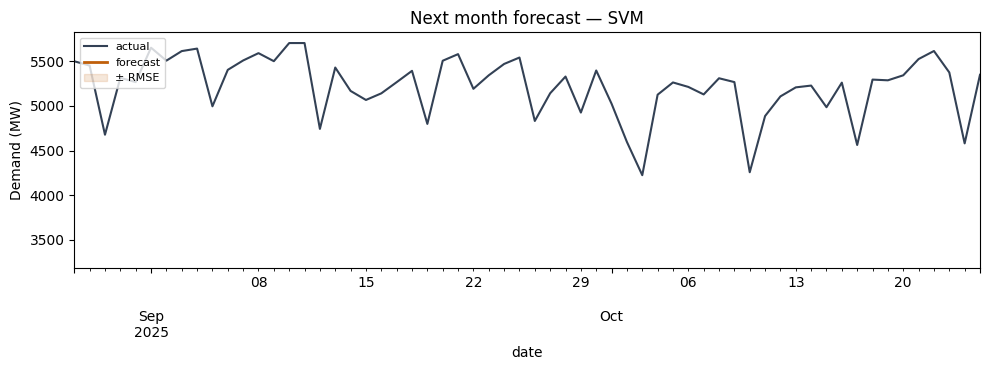

In [9]:
rmse = float(metrics.iloc[0]["RMSE"])
plt.figure(figsize=(10, 3.8))
hist.tail(60).plot(label="actual", color="#334155")
fmonth.index = fmonth.index
plt.plot(fmonth.index, fmonth.values, label="forecast", color="#C05F0A", linewidth=2)
plt.fill_between(fmonth.index, fmonth - rmse, fmonth + rmse,
                 color="#C05F0A", alpha=0.15, label="± RMSE")
plt.title(f"Next month forecast — {best_name}")
plt.ylabel("Demand (MW)")
plt.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()


## 7. Estimate the bill in BDT

In [10]:
SLABS = [(75, 5.26), (200, 8.50), (300, 9.10), (400, 9.62), (600, 15.01), (99999, 17.35)]
LIFELINE_RATE, LIFELINE_MAX = 4.63, 50
DEMAND_CHARGE, VAT = 42.0, 0.05

def bill_bdt(units, kw=1.0):
    if units <= LIFELINE_MAX:
        energy = units * LIFELINE_RATE
    else:
        energy, prev = 0.0, 0
        for limit, rate in SLABS:
            energy += max(0, min(units, limit) - prev) * rate
            prev = limit
    demand = DEMAND_CHARGE * kw
    vat = (energy + demand) * VAT
    return {"units": units, "energy": round(energy, 2),
            "demand": round(demand, 2), "vat": round(vat, 2),
            "total": round(energy + demand + vat, 2)}

pd.DataFrame([bill_bdt(u) for u in [50, 100, 150, 200, 250, 300, 400, 600]])


,units,energy,demand,vat,total
0,50,231.5,42.0,13.68,287.18
1,100,607.0,42.0,32.45,681.45
2,150,1032.0,42.0,53.70,1127.70
3,200,1457.0,42.0,74.95,1573.95
4,250,1912.0,42.0,97.70,2051.70
5,300,2367.0,42.0,120.45,2529.45
6,400,3329.0,42.0,168.55,3539.55
7,600,6331.0,42.0,318.65,6691.65


## 8. Detect anomalies

In [11]:
best_pred = preds[best_name]
resid = y_test - best_pred
z = (resid - resid.mean()) / resid.std()
anom = z[abs(z) > 3].sort_values(key=abs, ascending=False)

print(f"Anomalies found: {len(anom)}")
out = pd.DataFrame({
    "date": anom.index.date,
    "actual_mw": y_test[anom.index].round(0).values,
    "expected_mw": best_pred[anom.index].round(0).values,
    "z_score": anom.round(2).values,
    "type": np.where(anom.values > 0, "unusual HIGH", "unusual LOW"),
})
out


Anomalies found: 4


,date,actual_mw,expected_mw,z_score,type
0,2025-06-06,4981.0,3468.0,4.09,unusual HIGH
1,2025-06-07,3274.0,4315.0,-3.58,unusual LOW
2,2025-04-16,4355.0,5351.0,-3.44,unusual LOW
3,2025-04-05,3079.0,4006.0,-3.24,unusual LOW


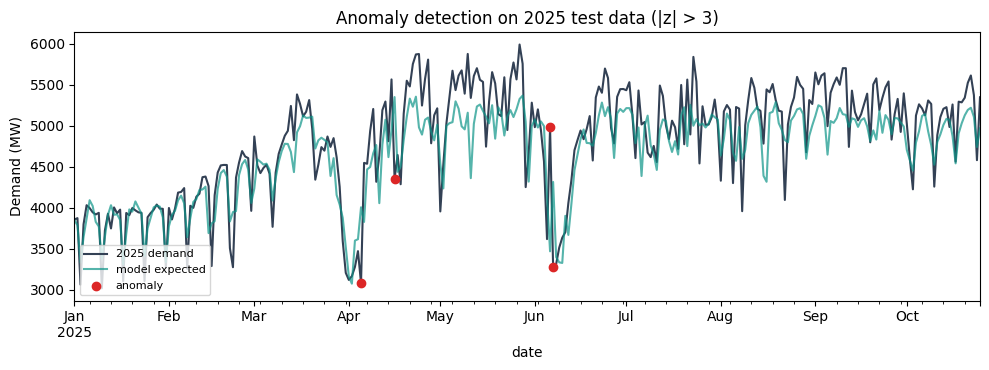

In [12]:
plt.figure(figsize=(10, 3.8))
y_test.plot(color="#334155", label="2025 demand")
best_pred.plot(color="#0D9488", alpha=0.7, label="model expected")
plt.scatter(anom.index, y_test[anom.index], color="#DC2626", zorder=5, label="anomaly")
plt.title(f"Anomaly detection on 2025 test data (|z| > 3)")
plt.ylabel("Demand (MW)")
plt.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()


## 9. Monthly model for the web app (user input)

In [13]:
monthly = d.resample("MS").sum() * 24 / 1000

mrows_data = []
for i in range(3, len(monthly)):
    base = monthly.iloc[i-3:i].mean()
    t = monthly.index[i]
    mrows_data.append({
        "r1": monthly.iloc[i-1] / base,
        "r2": monthly.iloc[i-2] / base,
        "r3": monthly.iloc[i-3] / base,
        "msin": np.sin(2 * np.pi * t.month / 12),
        "mcos": np.cos(2 * np.pi * t.month / 12),
        "target": monthly.iloc[i] / base,
        "base": base,
        "date": t,
    })
M = pd.DataFrame(mrows_data)
MFEAT = ["r1", "r2", "r3", "msin", "mcos"]
print(len(M), "monthly rows")
M.tail(3)


55 monthly rows


,r1,r2,r3,msin,mcos,target,base,date
52,1.018223,0.914768,1.067009,-0.866025,-5.000000e-01,1.025328,3715.672,2025-08-01
53,1.039775,1.032569,0.927656,-1.000000,-1.836970e-16,1.048611,3664.048,2025-09-01
54,1.007971,0.999477,0.992552,-0.866025,5.000000e-01,0.799772,3811.776,2025-10-01


In [14]:
mtrain, mtest = M[M.date <= "2024-12-01"], M[M.date >= "2025-01-01"]

mmodels = {
    "Linear Regression": LinearRegression(),
    "SVM": Pipeline([("scale", StandardScaler()), ("svr", SVR(kernel="rbf", C=100))]),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
}

mrows = []
for name, m in mmodels.items():
    m.fit(mtrain[MFEAT], mtrain["target"])
    p = m.predict(mtest[MFEAT]) * mtest["base"]
    act = mtest["target"] * mtest["base"]
    mrows.append({
        "model": name,
        "RMSE (GWh)": round(np.sqrt(mean_squared_error(act, p)), 1),
        "MAPE (%)": round(np.mean(np.abs((act - p) / act)) * 100, 2),
        "R2": round(r2_score(act, p), 4),
    })

mmetrics = pd.DataFrame(mrows).sort_values("RMSE (GWh)").reset_index(drop=True)
mbest_name = mmetrics.iloc[0]["model"]
mbest = mmodels[mbest_name]
print("BEST MONTHLY MODEL:", mbest_name)
mmetrics


BEST MONTHLY MODEL: Random Forest


,model,RMSE (GWh),MAPE (%),R2
0,Random Forest,269.0,5.04,0.5622
1,SVM,272.8,6.75,0.5498
2,Decision Tree,285.0,5.60,0.5087
3,Linear Regression,347.5,7.79,0.2695


In [15]:
mresid_std = float((mtest["target"] - mbest.predict(mtest[MFEAT])).std())
print("residual std (ratio scale):", round(mresid_std, 4))

def predict_user(m1, m2, m3, m4, month_no):
    base3 = (m1 + m2 + m3) / 3
    x4 = pd.DataFrame([[m3 / base3, m2 / base3, m1 / base3,
                        np.sin(2 * np.pi * month_no / 12),
                        np.cos(2 * np.pi * month_no / 12)]], columns=MFEAT)
    exp4 = float(mbest.predict(x4)[0]) * base3
    z4 = (m4 - exp4) / (mresid_std * base3)

    base4 = (m2 + m3 + m4) / 3
    nxt_no = month_no % 12 + 1
    x5 = pd.DataFrame([[m4 / base4, m3 / base4, m2 / base4,
                        np.sin(2 * np.pi * nxt_no / 12),
                        np.cos(2 * np.pi * nxt_no / 12)]], columns=MFEAT)
    nxt = float(mbest.predict(x5)[0]) * base4

    return {"expected_latest": round(exp4, 1), "z_score": round(z4, 2),
            "anomaly": "HIGH" if z4 > 3 else ("LOW" if z4 < -3 else "normal"),
            "next_month_kwh": round(nxt, 1)}

print("normal home :", predict_user(220, 210, 230, 240, 11))
print("sudden jump :", predict_user(200, 200, 200, 400, 11))


residual std (ratio scale): 0.0725
normal home : {'expected_latest': 193.2, 'z_score': 2.93, 'anomaly': 'normal', 'next_month_kwh': 188.1}
sudden jump : {'expected_latest': 175.0, 'z_score': 15.51, 'anomaly': 'HIGH', 'next_month_kwh': 233.9}


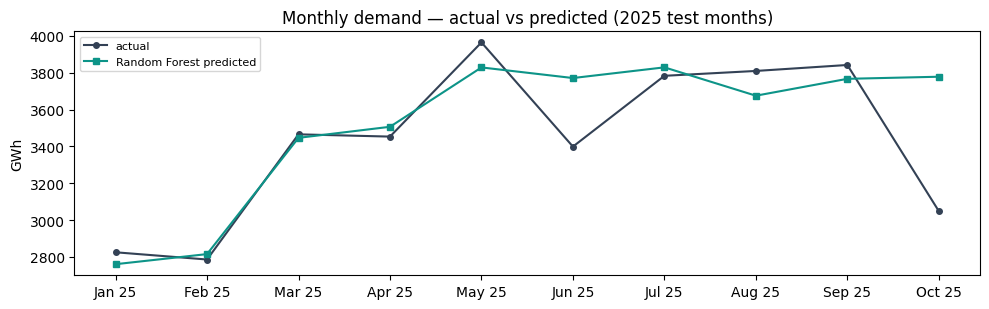

In [16]:
act = (mtest["target"] * mtest["base"]).values
mpred = (mbest.predict(mtest[MFEAT]) * mtest["base"]).values
lbl = mtest["date"].dt.strftime("%b %y")

plt.figure(figsize=(10, 3.2))
plt.plot(lbl, act, label="actual", color="#334155", marker="o", markersize=4)
plt.plot(lbl, mpred, label=f"{mbest_name} predicted", color="#0D9488", marker="s", markersize=4)
plt.title("Monthly demand — actual vs predicted (2025 test months)")
plt.ylabel("GWh")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()


## 10. Save outputs for the web app

In [17]:
import json
import joblib

OUT = "/kaggle/working" if PATH.startswith("/kaggle") else ("../output" if PATH.startswith("../") else "output")
os.makedirs(OUT, exist_ok=True)

df.to_csv(f"{OUT}/daily.csv", index=False)

with open(f"{OUT}/models.json", "w") as f:
    json.dump({"best_model": best_name,
               "test_period": "2025-01-01 to 2025-10-25",
               "results": rows}, f, indent=2)

with open(f"{OUT}/next_month.json", "w") as f:
    json.dump({
        "month": "2025-11",
        "month_name": "November 2025",
        "days": [{"date": str(ts.date()), "demand_mw": round(v, 1)}
                 for ts, v in fmonth.items()],
        "stats": {"total_gwh": round(total_gwh, 1), "avg_mw": round(avg_mw, 1),
                  "peak_mw": round(fmonth.max(), 1), "peak_date": str(peak_day.date()),
                  "last_year_gwh": round(last_nov.sum() * 24 / 1000, 1),
                  "yoy_pct": round(yoy, 1), "rmse_mw": round(rmse, 1)},
    }, f, indent=2)

pd.DataFrame({"date": X_test.index, "actual_mw": y_test.values,
              "predicted_mw": best_pred.round(1).values, "z": z.round(3).values,
              "is_anomaly": (abs(z) > 3).astype(int).values}
             ).to_csv(f"{OUT}/test_predictions.csv", index=False)

joblib.dump(mmodels, f"{OUT}/monthly_models.joblib")
with open(f"{OUT}/monthly_meta.json", "w") as f:
    json.dump({"best_model": mbest_name,
               "resid_std": round(mresid_std, 5),
               "features": MFEAT,
               "results": mrows}, f, indent=2)

mdays = d.resample("MS").count()
mout = pd.DataFrame({
    "month": mtest["date"].dt.strftime("%Y-%m"),
    "days": [int(mdays.loc[t]) for t in mtest["date"]],
    "actual_gwh": (mtest["target"] * mtest["base"]).round(1).values,
    "predicted_gwh": (mbest.predict(mtest[MFEAT]) * mtest["base"]).round(1).values,
})
mout.to_csv(f"{OUT}/monthly_test_predictions.csv", index=False)

print("saved to", OUT, ":", sorted(os.listdir(OUT)))


saved to ../output : ['daily.csv', 'models.json', 'monthly_meta.json', 'monthly_models.joblib', 'monthly_test_predictions.csv', 'next_month.json', 'test_predictions.csv']
